## Imports

In [30]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, precision_recall_curve, confusion_matrix, classification_report
import catboost as cb
import optuna
from optuna.samplers import TPESampler
import optuna.visualization.matplotlib as opt_plt

In [2]:
import sys
from pathlib import Path

src_path = Path.cwd().parent / "src"

if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

# модуль feature engineering
from feature_engineering import prepare_features, get_categorical_features

# команда для автообновления модулей
%load_ext autoreload
%autoreload 2

In [3]:
# Настройка стиля для графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [4]:
# Настройки
RANDOM_SEED = 29
np.random.seed(RANDOM_SEED)

## Train Data

In [5]:
TRAIN_PATH = Path("../data/processed/train.csv")

In [6]:
# Загрузка и подготовка
X, y = prepare_features(str(TRAIN_PATH))
X.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,is_germany,is_single_product,is_3plus_products,is_age_over_45,is_zero_balance,is_high_balance_inactive
0,710,France,Female,36,7,0.00,1,1,1,62367.35,0,1,0,0,1,0
1,582,France,Male,37,4,0.00,1,1,0,127939.18,0,1,0,0,1,0
2,731,France,Male,41,4,0.00,1,1,1,86410.29,0,1,0,0,1,0
3,587,Germany,Male,54,0,76319.64,1,1,0,129870.93,1,1,0,1,0,0
4,567,Germany,Male,34,1,143500.82,2,0,1,110472.12,1,0,0,0,0,0


In [7]:
print(f"\nРазмер X: {X.shape}")
print(f"Размер y: {y.shape}")
print(f"\nРаспределение таргета:")
print(y.value_counts())
print(f"\nДоля оттока: {y.mean():.2%}")
print(f"\nКатегориальные признаки: {get_categorical_features()}")


Размер X: (12000, 16)
Размер y: (12000,)

Распределение таргета:
Exited
0    9586
1    2414
Name: count, dtype: int64

Доля оттока: 20.12%

Категориальные признаки: ['Geography', 'Gender', 'HasCrCard', 'IsActiveMember']


## Model

#### Baseline-модель

In [8]:
cat_features = get_categorical_features()

# Простая кросс-валидация
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
cv_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    model = cb.CatBoostClassifier(
        iterations=500,
        learning_rate=0.1,
        depth=6,
        l2_leaf_reg=10,
        auto_class_weights='Balanced',
        eval_metric='AUC',
        loss_function='Logloss',
        task_type='GPU',
        devices='0',
        random_seed=RANDOM_SEED,
        verbose=0
    )

    model.fit(
        X_train, y_train,
        cat_features=cat_features,
        eval_set=(X_val, y_val),
        early_stopping_rounds=50,
        verbose=0
    )
    
    y_pred = model.predict_proba(X_val)[:, 1]
    score = roc_auc_score(y_val, y_pred)
    cv_scores.append(score)
    print(f"Fold {fold + 1}: ROC AUC = {score:.4f}")

print(f"\n Средний ROC AUC: {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f}")

Default metric period is 5 because AUC is/are not implemented for GPU


Fold 1: ROC AUC = 0.9379


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 2: ROC AUC = 0.9368


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 3: ROC AUC = 0.9316


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 4: ROC AUC = 0.9364


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 5: ROC AUC = 0.9248

 Средний ROC AUC: 0.9335 ± 0.0049


#### Optuna

In [9]:
def objective(trial):
    """
    Целевая функция для Optuna.
    Возвращает средний ROC AUC по 5 фолдам.
    """
    # Пространство поиска гиперпараметров
    params = {
        'iterations': trial.suggest_int('iterations', 500, 2500),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 30),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 50, 200),
        'max_bin': trial.suggest_int('max_bin', 150, 300),
        'random_strength': trial.suggest_float('random_strength', 0.01, 1.0),
        'bootstrap_type': trial.suggest_categorical('bootstrap_type', ['Bayesian', 'Bernoulli', 'MVS']),
        'auto_class_weights': trial.suggest_categorical('auto_class_weights', ['Balanced', 'SqrtBalanced', None]),
    }
    
    # Кросс-валидация
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    cv_scores = []
    
    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
        
        model = cb.CatBoostClassifier(
            **params,
            eval_metric='AUC',
            loss_function='Logloss',
            task_type='GPU',
            devices='0',
            random_seed=RANDOM_SEED,
            verbose=0
        )
        
        model.fit(
            X_train, y_train,
            cat_features=cat_features,
            eval_set=(X_val, y_val),
            early_stopping_rounds=100,
            verbose=0
        )
        
        y_pred = model.predict_proba(X_val)[:, 1]
        score = roc_auc_score(y_val, y_pred)
        cv_scores.append(score)

        # Prune
        running_mean_score = np.mean(cv_scores)
        trial.report(running_mean_score, step=fold)
        if trial.should_prune():
            raise optuna.TrialPruned()
    
    return np.mean(cv_scores)

Запуск Optuna:

In [10]:
# Настройки Optuna
pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1)
sampler = TPESampler(seed=RANDOM_SEED)

study = optuna.create_study(
    study_name='catboost_bank_churn',
    direction='maximize',
    sampler=sampler
)

# Запуск оптимизации
N_TRIALS = 100

study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

# Результаты
print("\n" + "-" * 40)
print("Лучшие параметры:")
print("-" * 40)
print(f"Best ROC AUC: {study.best_value:.4f}")
print("\nBest params:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

[I 2026-07-16 16:22:24,183] A new study created in memory with name: catboost_bank_churn
  0%|          | 0/100 [00:00<?, ?it/s]Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Best trial: 0. Best value: 0.934055:   1%|          | 1/100 [00:38<1:03:38, 38.57s/it]

[I 2026-07-16 16:23:02,750] Trial 0 finished with value: 0.9340549879648309 and parameters: {'iterations': 2228, 'learning_rate': 0.026353642901057864, 'depth': 4, 'l2_leaf_reg': 23.133878925578266, 'min_data_in_leaf': 118, 'max_bin': 231, 'random_strength': 0.7293694249992322, 'bootstrap_type': 'Bayesian', 'auto_class_weights': 'SqrtBalanced'}. Best is trial 0 with value: 0.9340549879648309.


Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Best trial: 0. Best value: 0.934055:   2%|▏         | 2/100 [01:00<47:20, 28.98s/it]  

[I 2026-07-16 16:23:25,020] Trial 1 finished with value: 0.9340215154720182 and parameters: {'iterations': 1319, 'learning_rate': 0.07980626673549528, 'depth': 5, 'l2_leaf_reg': 9.284485898843624, 'min_data_in_leaf': 153, 'max_bin': 276, 'random_strength': 0.8110618858998132, 'bootstrap_type': 'Bernoulli', 'auto_class_weights': 'Balanced'}. Best is trial 0 with value: 0.9340549879648309.


Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Best trial: 0. Best value: 0.934055:   3%|▎         | 3/100 [02:07<1:14:33, 46.12s/it]

[I 2026-07-16 16:24:31,531] Trial 2 finished with value: 0.9339361841664113 and parameters: {'iterations': 1968, 'learning_rate': 0.048809474268081424, 'depth': 8, 'l2_leaf_reg': 13.701638337104312, 'min_data_in_leaf': 69, 'max_bin': 246, 'random_strength': 0.4838572660213203, 'bootstrap_type': 'MVS', 'auto_class_weights': 'SqrtBalanced'}. Best is trial 0 with value: 0.9340549879648309.


... (190 outputs left out)

Default metric period is 5 because AUC is/are not implemented for GPU
Best trial: 69. Best value: 0.934585:  99%|█████████▉| 99/100 [25:31<00:05,  5.36s/it]

[I 2026-07-16 16:47:55,367] Trial 98 pruned. 


Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Best trial: 69. Best value: 0.934585: 100%|██████████| 100/100 [25:54<00:00, 15.54s/it]

[I 2026-07-16 16:48:18,198] Trial 99 finished with value: 0.9343756559521532 and parameters: {'iterations': 851, 'learning_rate': 0.06634481297399358, 'depth': 4, 'l2_leaf_reg': 11.103164159650643, 'min_data_in_leaf': 163, 'max_bin': 270, 'random_strength': 0.6331959375397958, 'bootstrap_type': 'Bayesian', 'auto_class_weights': 'SqrtBalanced'}. Best is trial 69 with value: 0.9345847106087547.

----------------------------------------
Лучшие параметры:
----------------------------------------
Best ROC AUC: 0.9346

Best params:
  iterations: 572
  learning_rate: 0.08821111218006195
  depth: 4
  l2_leaf_reg: 15.283527913327964
  min_data_in_leaf: 120
  max_bin: 261
  random_strength: 0.403432186841754
  bootstrap_type: Bernoulli
  auto_class_weights: SqrtBalanced


<Figure size 1000x600 with 0 Axes>

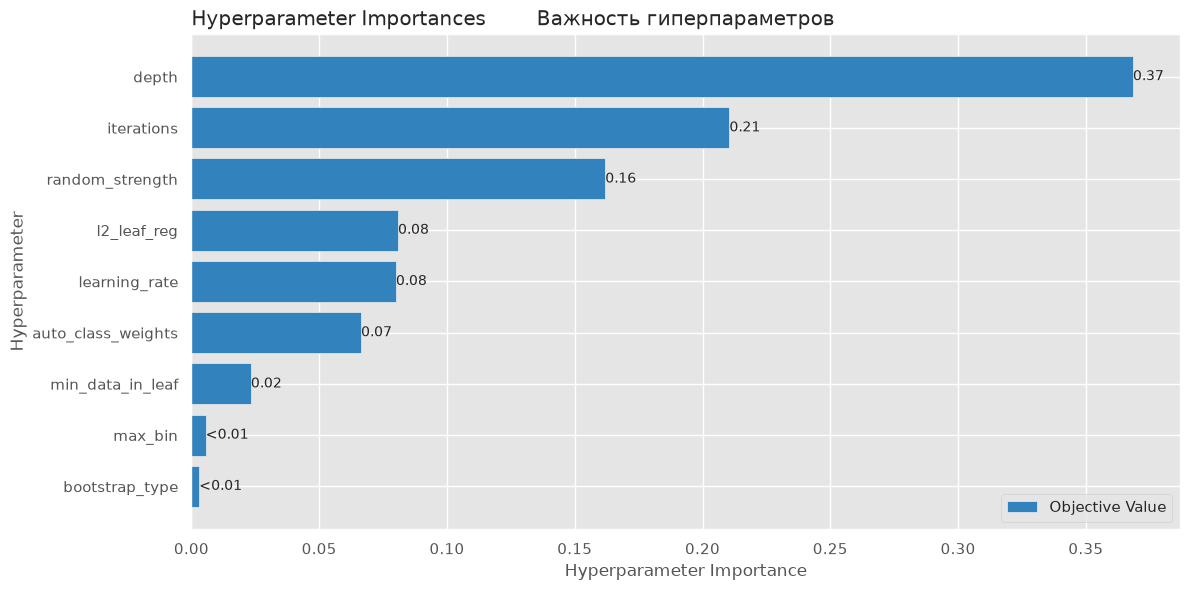

<Figure size 1000x600 with 0 Axes>

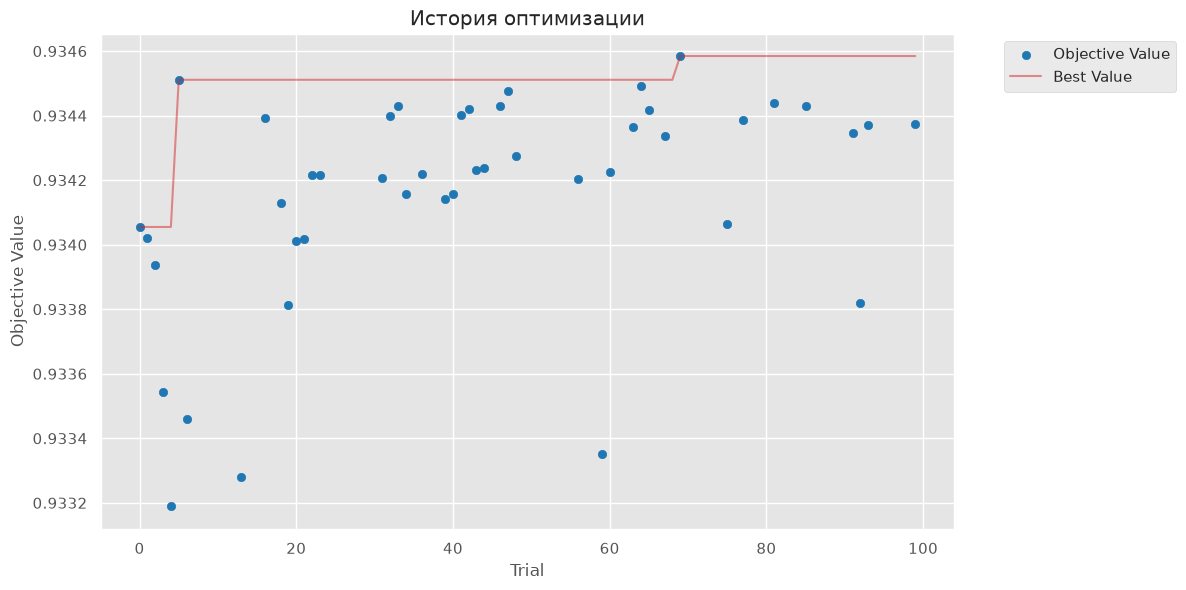

In [14]:
# Важность параметров
plt.figure(figsize=(10, 6))
opt_plt.plot_param_importances(study)
plt.title('Важность гиперпараметров')
plt.tight_layout()
plt.show()

# История оптимизации
plt.figure(figsize=(10, 6))
opt_plt.plot_optimization_history(study)
plt.title('История оптимизации')
plt.tight_layout()
plt.show()

In [18]:
# Лучшие параметры
best_params = study.best_params

#### Финальная модель

In [19]:
# Обучаем финальную модель на всех данных

final_model = cb.CatBoostClassifier(
    **best_params,
    eval_metric='AUC',
    loss_function='Logloss',
    task_type='CPU',
    devices='0',
    random_seed=RANDOM_SEED,
    verbose=100
)

final_model.fit(X, y, cat_features=cat_features)

0:	total: 5.68ms	remaining: 3.24s
100:	total: 377ms	remaining: 1.76s
200:	total: 726ms	remaining: 1.34s
300:	total: 1.07s	remaining: 962ms
400:	total: 1.42s	remaining: 607ms
500:	total: 1.79s	remaining: 254ms
571:	total: 2.04s	remaining: 0us


CatBoostClassifier(auto_class_weights='SqrtBalanced', bootstrap_type='Bernoulli', depth=4, devices='0', eval_metric='AUC', iterations=572, l2_leaf_reg=15.283527913327964, learning_rate=0.08821111218006195, loss_function='Logloss', max_bin=261, min_data_in_leaf=120, random_seed=29, random_strength=0.403432186841754, task_type='CPU', verbose=100)

In [20]:
# Сохранение модели
final_model.save_model('../artefacts/final_catboost_model_v3.cbm')
print("Модель сохранена: ../artefacts/final_catboost_model_v3.cbm")

Модель сохранена: ../artefacts/final_catboost_model_v3.cbm


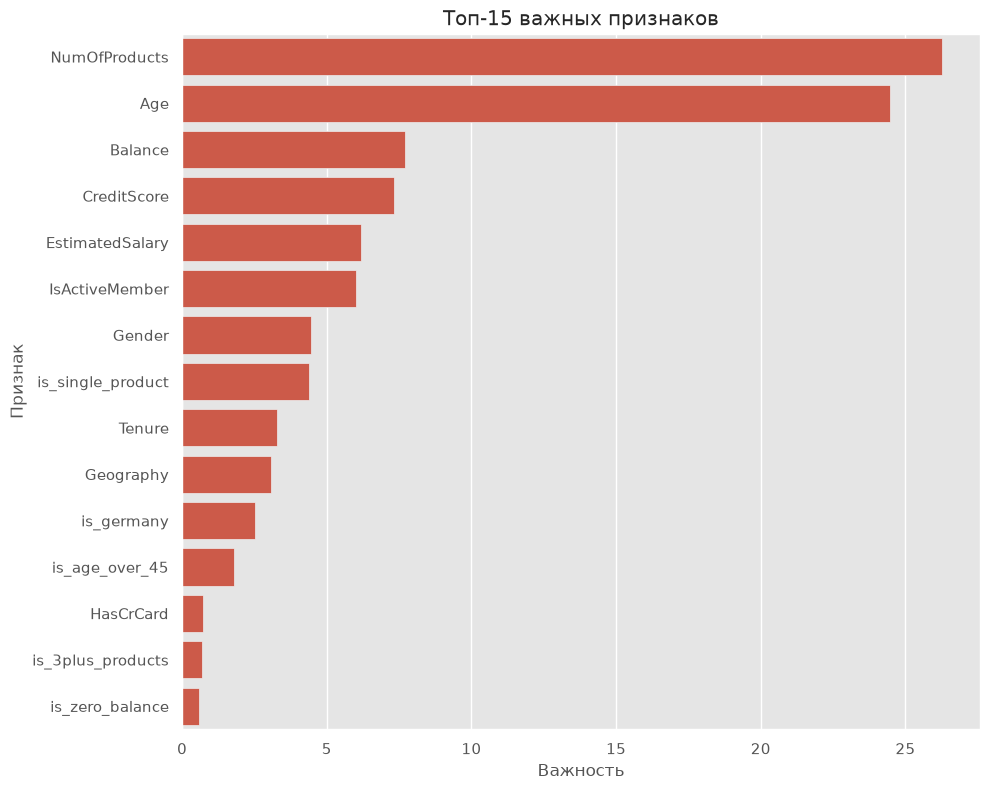

In [21]:
# Анализ важности признаков
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': final_model.get_feature_importance()
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=feature_importance.head(15), x='importance', y='feature')
plt.title('Топ-15 важных признаков')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

#### Финальная оценка (на отложенной выборке)

In [22]:
# Загрузка и подготовка валидационных данных
VAL_PATH = Path("../data/processed/val.csv")
X_val, y_val = prepare_features(str(VAL_PATH))

print(f"Размер валидационной выборки: {X_val.shape}")
print(f"Таргет присутствует: {y_val is not None}")

Размер валидационной выборки: (3000, 16)
Таргет присутствует: True


In [23]:
# Генерация предсказаний
y_val_pred_proba = final_model.predict_proba(X_val)[:, 1]

# Базовый порог 0.5
threshold = 0.5
y_val_pred = (y_val_pred_proba >= threshold).astype(int)

print(f"Статистика предсказаний (порог {threshold}):")
print(f"Вероятности: min={y_val_pred_proba.min():.4f}, max={y_val_pred_proba.max():.4f}, mean={y_val_pred_proba.mean():.4f}")
print(f"Бинарные предсказания: {y_val_pred.sum()} уйдут ({y_val_pred.mean():.1%}), {len(y_val_pred) - y_val_pred.sum()} останутся")

Статистика предсказаний (порог 0.5):
Вероятности: min=0.0010, max=0.9986, mean=0.2511
Бинарные предсказания: 640 уйдут (21.3%), 2360 останутся


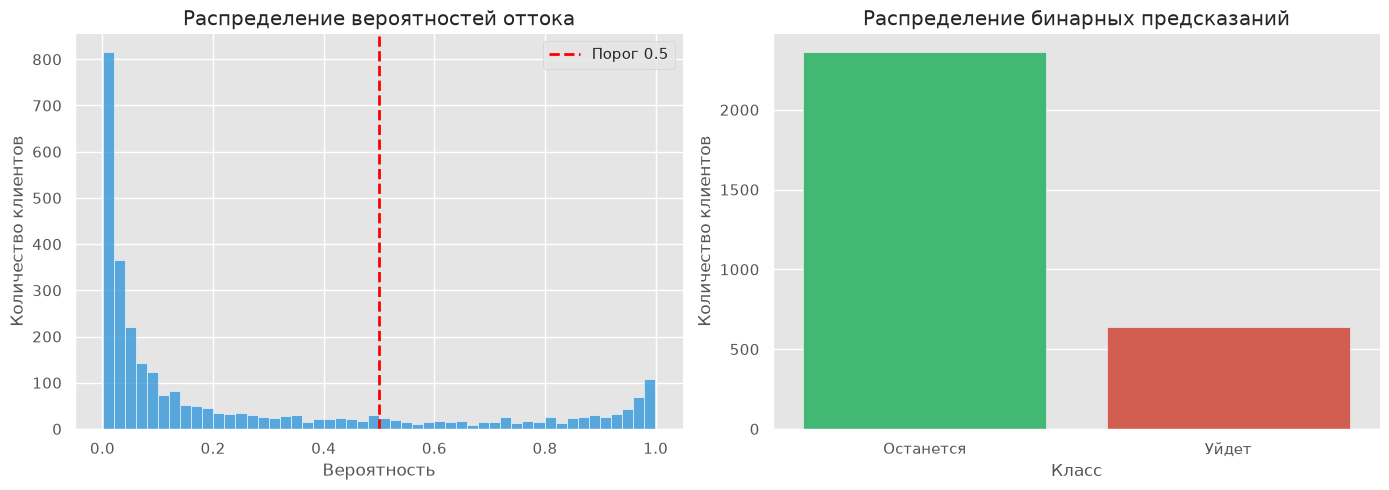

In [24]:
# Визуализация распределения
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.hist(y_val_pred_proba, bins=50, edgecolor='white', alpha=0.8, color='#3498db')
plt.axvline(x=threshold, color='red', linestyle='--', linewidth=2, label=f'Порог {threshold}')
plt.title('Распределение вероятностей оттока')
plt.xlabel('Вероятность')
plt.ylabel('Количество клиентов')
plt.legend()

plt.subplot(1, 2, 2)
sns.countplot(x=y_val_pred, palette=['#2ecc71', '#e74c3c'])
plt.xticks(ticks=[0, 1], labels=['Останется', 'Уйдет'])
plt.title('Распределение бинарных предсказаний')
plt.xlabel('Класс')
plt.ylabel('Количество клиентов')
sns.despine() # Убираем лишние рамки

plt.tight_layout()
plt.show()

In [25]:
# Анализ уверенности модели
print(f"Анализ уверенности модели:")
high_confidence = (y_val_pred_proba >= 0.8) | (y_val_pred_proba <= 0.2)
low_confidence = (y_val_pred_proba > 0.2) & (y_val_pred_proba < 0.8)

print(f"\nВысокая уверенность (p ≤ 0.2 или p ≥ 0.8): {high_confidence.sum()} клиентов ({high_confidence.mean():.1%})")
print(f"Низкая уверенность (0.2 < p < 0.8): {low_confidence.sum()} клиентов ({low_confidence.mean():.1%})")

Анализ уверенности модели:

Высокая уверенность (p ≤ 0.2 или p ≥ 0.8): 2361 клиентов (78.7%)
Низкая уверенность (0.2 < p < 0.8): 639 клиентов (21.3%)


In [28]:
# Топ клиентов по вероятности оттока
print(f"\nТоп-10 клиентов с наивысшей вероятностью оттока:")
top_churn_idx = np.argsort(y_val_pred_proba)[-10:][::-1]

# Создаем DataFrame для наглядного отображения признаков этих клиентов
top_churn_df = X_val.iloc[top_churn_idx].copy()
top_churn_df['Churn_Probability'] = y_val_pred_proba[top_churn_idx]

# Показываем только самые информативные столбцы
cols_to_show = ['Churn_Probability', 'Age', 'Balance', 'Geography', 'NumOfProducts', 'is_high_balance_inactive']
available_cols = [c for c in cols_to_show if c in top_churn_df.columns]
display(top_churn_df[available_cols].style.format({'Churn_Probability': '{:.2%}'}))


Топ-10 клиентов с наивысшей вероятностью оттока:


,Churn_Probability,Age,Balance,Geography,NumOfProducts,is_high_balance_inactive
964,99.86%,62,0.000000,Spain,3,0
1313,99.85%,53,97560.160000,Germany,3,0
1428,99.84%,54,133658.240000,Germany,1,1
327,99.69%,55,123835.520000,Germany,1,1
268,99.68%,56,131778.080000,Germany,1,1
2861,99.65%,56,0.000000,France,3,0
2302,99.62%,54,136674.010000,Germany,1,1
378,99.62%,53,0.000000,France,3,0
1146,99.60%,53,126041.020000,Germany,1,1
614,99.60%,52,101851.800000,Germany,1,1


Метрики качества:
  ROC AUC:   0.9325
  Accuracy:  0.8883
  F1-Score:  0.7305 (для класса 'Exited')


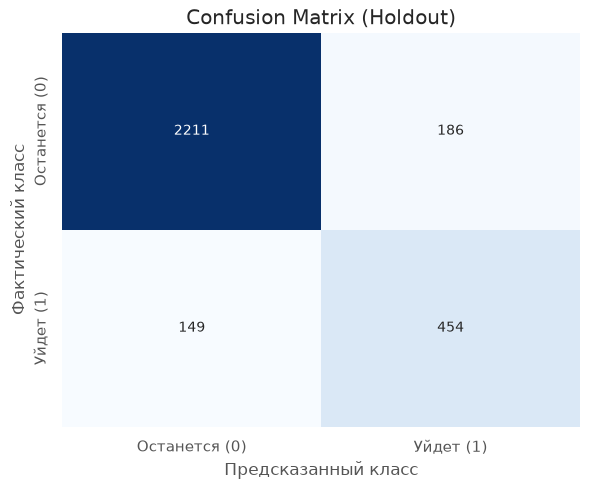


Classification Report:
               precision    recall  f1-score   support

Останется (0)       0.94      0.92      0.93      2397
    Уйдет (1)       0.71      0.75      0.73       603

     accuracy                           0.89      3000
    macro avg       0.82      0.84      0.83      3000
 weighted avg       0.89      0.89      0.89      3000


Оптимальный порог отсечения по F1-score = 0.60
При этом пороге F1-Score для класса 'Уйдет' составит 0.7409 (текущий при 0.5: 0.7305)


In [ ]:
# Вычисление метрик
if y_val is not None:
    print("Метрики качества:")
    print("-" * 40)
    
    roc_auc = roc_auc_score(y_val, y_val_pred_proba)
    accuracy = accuracy_score(y_val, y_val_pred)
    f1 = f1_score(y_val, y_val_pred)
    
    print(f"  ROC AUC:   {roc_auc:.4f}")
    print(f"  Accuracy:  {accuracy:.4f}")
    print(f"  F1-Score:  {f1:.4f} (для класса 'Exited')")
    
    # Confusion Matrix
    cm = confusion_matrix(y_val, y_val_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Останется (0)', 'Уйдет (1)'],
                yticklabels=['Останется (0)', 'Уйдет (1)'])
    plt.title('Confusion Matrix (Holdout)')
    plt.ylabel('Фактический класс')
    plt.xlabel('Предсказанный класс')
    plt.tight_layout()
    plt.show()
    
    print(f"\nClassification Report:")
    print(classification_report(y_val, y_val_pred, target_names=['Останется (0)', 'Уйдет (1)']))
    
    # Поиск оптимального порога по F1-score
    precisions, recalls, thresholds_pr = precision_recall_curve(y_val, y_val_pred_proba)
    # Обрезаем массивы, чтобы избежать IndexError
    # Последний элемент precisions/recalls соответствует recall=0 (порог > max_proba), 
    # где F1 всегда равен 0. Он не имеет соответствующего значения в thresholds_pr.
    precisions = precisions[:-1]
    recalls = recalls[:-1]
    
    # Теперь длины массивов совпадают
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
    best_threshold_idx = np.argmax(f1_scores)
    best_threshold = thresholds_pr[best_threshold_idx]
    best_f1 = f1_scores[best_threshold_idx]
    
    print(f"\nОптимальный порог отсечения по F1-score = {best_threshold:.2f}")
    print(f"При этом пороге F1-Score для класса 'Уйдет' составит {best_f1:.4f} (текущий при 0.5: {f1:.4f})")
else:
    print("\nТаргет отсутствует (слепой тестовый набор). Метрики вычислить невозможно.")

## Summary: 

- ROC AUC = 0.9325 - отличный показатель. Модель хорошо разделяет классы.  
- F1-Score = 0.73 для класса "Exited" с хорошим балансом precision/recall.  
- Высокая уверенность модели - 78.7% клиентов классифицированы с уверенностью ≥80%  
- Порог 0.60 дает небольшое улучшение F1 (0.7305 → 0.7409), но при повышении порога уменьшится recall и мы пропустим больше уходящих. Пожалуй для бизнеса важнее найти всех, кто потенциально может уйти, поэтому стоит остаться на пороге 0.5 или даже снизить до 0.45.